In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
from PIL import Image
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.optimizers import Adam

# Some global variables
# root
ROOT = Path.cwd().parent
DATA = ROOT / "data"
IMG_SIZE = (128, 128)
BATCH_SIZE = 64
SEED = 42

tf.keras.utils.set_random_seed(SEED)
print(f"tensorflow: {tf.__version__}\ndataset found: {DATA.is_dir()}\nFolder path: {DATA}")

I0000 00:00:1794908053.709609    1559 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


tensorflow: 2.23.0-dev20261112
dataset found: True
Folder path: /home/ishan/projects/DL/potato_leaf/data


# check the class folders (x and y) in the dataset directory

In [2]:
classes = sorted(p.name for p in DATA.iterdir() if p.is_dir()) if DATA.exists() else []
counts = {name: len([p for p in (DATA/name).iterdir() if p.suffix.lower() in [".jpg", ".jpeg", ".png"]]) for name in classes}
print("image per class:", counts)

#optional:
assert len(classes) == 3 and all(v > 0 for v in counts.values()), "Dataset should have 3 classes with at least one image in each."

image per class: {'Potato___Early_blight': 1000, 'Potato___Late_blight': 1000, 'Potato___healthy': 152}


# display three real images: open actual file per class, convert it into RGB and display it.

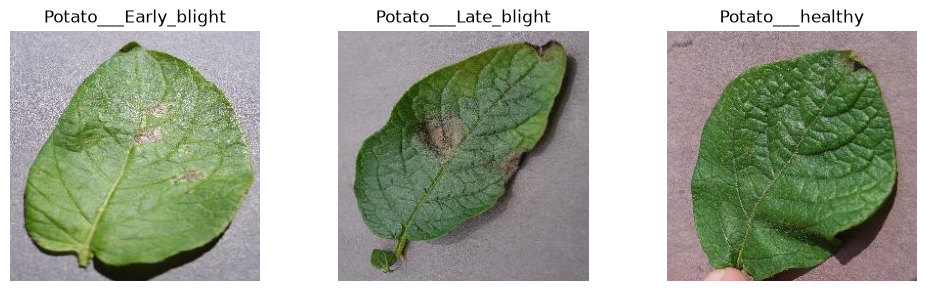

In [3]:
fig, axes = plt.subplots(1, 3, figsize = (10, 3))
for i, name in zip(axes, classes):
    folder = DATA/name
    file = next(p for p in folder.iterdir() if p.suffix.lower() in ['.jpg', '.jpeg', '.png'])
    with Image.open(file) as img:
        img = img.convert("RGB")
        i.imshow(img)
        i.set_title(name)
        i.axis("off")

plt.tight_layout()
plt.show()

# Split data in training and validation

In [4]:
train_ds = tf.keras.utils.image_dataset_from_directory(DATA, validation_split=0.2, subset="training", seed=SEED, image_size=IMG_SIZE, batch_size=BATCH_SIZE, color_mode="rgb", label_mode="int")
validation_ds = tf.keras.utils.image_dataset_from_directory(DATA, validation_split=0.2, subset="validation", seed=SEED, image_size=IMG_SIZE, batch_size=BATCH_SIZE, color_mode="rgb", label_mode="int")

class_names = train_ds.class_names

images, labels = next(iter(train_ds))

print(f"class order: {class_names}\nimage in one batch: {images.shape}\nlabels in one batch: {labels[:8].numpy()}")

Found 2152 files belonging to 3 classes.
Using 1722 files for training.


I0000 00:00:1794908066.261480    1559 service.cc:155] XLA service 0x8e6e560 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1794908066.261523    1559 service.cc:171]   StreamExecutor [0]: NVIDIA GeForce GTX 1650, Compute Capability 7.5 (Driver: 13.5.0[621.1.0]; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.28.1)
I0000 00:00:1794908066.316631    1559 gpu_device.cc:1908] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 2244 MB memory:  -> device: 0, name: NVIDIA GeForce GTX 1650, pci bus id: 0000:01:00.0, compute capability: 7.5
libunwind: __unw_add_dynamic_fde: bad fde: FDE is really a CIE


Found 2152 files belonging to 3 classes.
Using 430 files for validation.


libunwind: __unw_add_dynamic_fde: bad fde: FDE is really a CIE


class order: ['Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy']
image in one batch: (64, 128, 128, 3)
labels in one batch: [1 1 0 0 0 0 0 0]


# Data augmentation: rotation, zoom, horizontal, vertical.


libunwind: __unw_add_dynamic_fde: bad fde: FDE is really a CIE
libunwind: __unw_add_dynamic_fde: bad fde: FDE is really a CIE
libunwind: __unw_add_dynamic_fde: bad fde: FDE is really a CIE
libunwind: __unw_add_dynamic_fde: bad fde: FDE is really a CIE
libunwind: __unw_add_dynamic_fde: bad fde: FDE is really a CIE


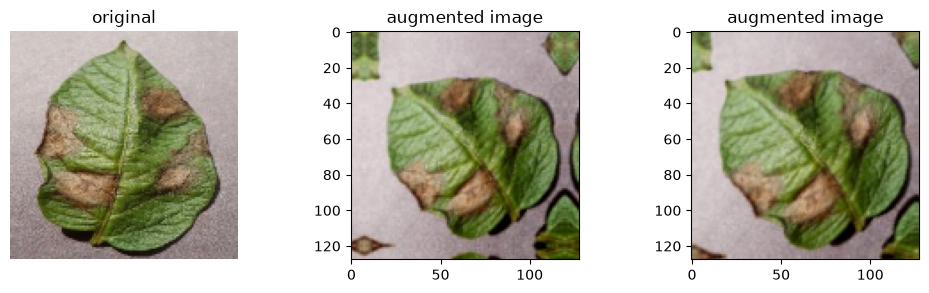

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

In [5]:
augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal_and_vertical"),
    tf.keras.layers.RandomRotation(0.15),
    tf.keras.layers.RandomZoom(height_factor=(-0.2, 0.2)),
    tf.keras.layers.RandomContrast(0.2),
])

sample = images[0:1]
fig, axes = plt.subplots(1, 3, figsize=(10, 3))
axes[0].imshow(tf.cast(sample[0], tf.uint8))
axes[0].set_title("original")

for i in (1, 2):
    augmented = augmentation(sample, training=True)[0]
    axes[i].imshow(tf.cast(tf.clip_by_value(augmented, 0, 255), tf.uint8))
    axes[i].set_title("augmented image")

for i in axes:
    i.axis("off")
    plt.tight_layout()
    plt.show()

# Creating the model with all the layers

In [6]:
model = tf.keras.Sequential([
    # Input with height=128, weight=128, color=rgb/3channels
    tf.keras.Input(shape=(128,128,3)),

    # Rescaling the value and preforming augmentation
    tf.keras.layers.Rescaling(1.0/255),
    augmentation,

    # Feature extraction
    tf.keras.layers.Conv2D(32, 3, padding='same', use_bias=False),
    tf.keras.layers.BatchNormalization(momentum=0.9),
    tf.keras.layers.Activation('relu'),
    tf.keras.layers.MaxPooling2D(),

    tf.keras.layers.Conv2D(64, 3, padding='same', use_bias=False),
    tf.keras.layers.BatchNormalization(momentum=0.9),
    tf.keras.layers.Activation('relu'),
    tf.keras.layers.MaxPooling2D(),

    tf.keras.layers.Conv2D(128, 3, padding='same', use_bias=False),
    tf.keras.layers.BatchNormalization(momentum=0.9),
    tf.keras.layers.Activation('relu'),
    tf.keras.layers.MaxPooling2D(),

    tf.keras.layers.Conv2D(256, 3, padding='same', use_bias=False),
    tf.keras.layers.BatchNormalization(momentum=0.9),
    tf.keras.layers.Activation('relu'),
    tf.keras.layers.MaxPooling2D(),

    tf.keras.layers.Conv2D(512, 3, padding='same', use_bias=False),
    tf.keras.layers.BatchNormalization(momentum=0.9),
    tf.keras.layers.Activation('relu'),
    tf.keras.layers.MaxPooling2D(),
    
    # Flattening
    # tf.keras.layers.Flatten(),
    tf.keras.layers.GlobalAveragePooling2D(),

    # Classifier
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.Dense(3, activation='softmax')
])

model.summary()


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 256)    │       294,912 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 16, 16, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 16, 16, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 8, 8, 512)      │     1,179,648 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 8, 8, 512)      │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 8, 8, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 4, 4, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 1,637,603 (6.25 MB)

 Trainable params: 1,635,619 (6.24 MB)

 Non-trainable params: 1,984 (7.75 KB)

In [7]:
import tensorflow as tf

print("TensorFlow version:", tf.__version__)

print("\nAvailable GPUs:")

gpus = tf.config.list_physical_devices('GPU')

for gpu in gpus:
    print(gpu)

if not gpus:
    print("No GPU detected. Training may be running on CPU.")

TensorFlow version: 2.23.0-dev20261112

Available GPUs:
PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')


# Adam optimizer and training

In [8]:

train_labels = np.concatenate([y.numpy() for _, y in train_ds])

class_counts = np.bincount(train_labels, minlength=len(class_names))
class_weights = {i: len(train_labels)/(len(class_names)*count) for i, count in enumerate(class_counts)}
class_weights = {i: float(np.sqrt(w)) for i, w in class_weights.items()}
print(f"training class counts: {dict(zip(class_names, class_counts))}\n class weights: {class_weights}")

model.compile(optimizer=Adam(learning_rate=0.0000075), loss="sparse_categorical_crossentropy", metrics=['accuracy'])

#apply callback (model_check_point)
callbacks_list = [
    EarlyStopping(monitor='val_loss', patience=6, restore_best_weights=True, verbose=1),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=4, min_lr=5e-7, verbose=1)
]
history = model.fit(train_ds, validation_data=validation_ds, epochs=60, class_weight=class_weights, callbacks=callbacks_list)

training class counts: {'Potato___Early_blight': np.int64(818), 'Potato___Late_blight': np.int64(792), 'Potato___healthy': np.int64(112)}
 class weights: {0: 0.8376822138750128, 1: 0.8513210174472816, 2: 2.2638462845343543}
Epoch 1/60


/home/ishan/projects/DL/potato_leaf/venv/lib/python3.14/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
W0000 00:00:1794908075.785240    1559 prefetch_autotuner.cc:56] Prefetch autotuner tried to allocate 16777728 bytes after encountering the first element of size 16777728 bytes.This already causes the autotune ram budget to be exceeded. To stay within the ram budget, either increase the ram budget or reduce element size
libunwind: __unw_add_dynamic_fde: bad fde: FDE is really a CIE
libunwind: __unw_add_dynamic_fde: bad fde: FDE is really a CIE
I0000 00:00:1794908083.003896    1913 cuda_dnn.cc:505] Loaded cuDNN version 92801
libunwind: __unw_add_dynamic_fde: bad fde: FDE is really a CIE
libunwind: __unw_add_dynamic_fde: bad fde: FDE is r

 1/27 ━━━━━━━━━━━━━━━━━━━━ 7:43 18s/step - accuracy: 0.3594 - loss: 1.2389

W0000 00:00:1794908093.571309    1559 prefetch_dataset_op.cc:478] SEVERE STARVATION: Element UID 1794908075785349118 in buffer 'PrefetchDataset/_20' sat unconsumed for 17.7858 seconds!


27/27 ━━━━━━━━━━━━━━━━━━━━ 31s 495ms/step - accuracy: 0.6870 - loss: 0.8189 - val_accuracy: 0.4837 - val_loss: 0.9474 - learning_rate: 7.5000e-06
Epoch 2/60
 1/27 ━━━━━━━━━━━━━━━━━━━━ 5s 223ms/step - accuracy: 0.8438 - loss: 0.4213

W0000 00:00:1794908106.449484    1559 prefetch_autotuner.cc:56] Prefetch autotuner tried to allocate 16777728 bytes after encountering the first element of size 16777728 bytes.This already causes the autotune ram budget to be exceeded. To stay within the ram budget, either increase the ram budget or reduce element size


... (7 outputs left out)

W0000 00:00:1794908167.449162    1559 prefetch_autotuner.cc:56] Prefetch autotuner tried to allocate 16777728 bytes after encountering the first element of size 16777728 bytes.This already causes the autotune ram budget to be exceeded. To stay within the ram budget, either increase the ram budget or reduce element size


27/27 ━━━━━━━━━━━━━━━━━━━━ 5s 187ms/step - accuracy: 0.9431 - loss: 0.1622 - val_accuracy: 0.8884 - val_loss: 0.2535 - learning_rate: 7.5000e-06
Epoch 15/60
 1/27 ━━━━━━━━━━━━━━━━━━━━ 5s 217ms/step - accuracy: 0.9219 - loss: 0.1775

W0000 00:00:1794908172.522893    1559 prefetch_autotuner.cc:56] Prefetch autotuner tried to allocate 16777728 bytes after encountering the first element of size 16777728 bytes.This already causes the autotune ram budget to be exceeded. To stay within the ram budget, either increase the ram budget or reduce element size


27/27 ━━━━━━━━━━━━━━━━━━━━ 5s 191ms/step - accuracy: 0.9489 - loss: 0.1592 - val_accuracy: 0.9256 - val_loss: 0.1829 - learning_rate: 7.5000e-06
Epoch 16/60
27/27 ━━━━━━━━━━━━━━━━━━━━ 5s 187ms/step - accuracy: 0.9419 - loss: 0.1683 - val_accuracy: 0.9070 - val_loss: 0.2101 - learning_rate: 7.5000e-06
Epoch 17/60
27/27 ━━━━━━━━━━━━━━━━━━━━ 5s 186ms/step - accuracy: 0.9518 - loss: 0.1437 - val_accuracy: 0.9209 - val_loss: 0.1758 - learning_rate: 7.5000e-06
Epoch 18/60
27/27 ━━━━━━━━━━━━━━━━━━━━ 5s 188ms/step - accuracy: 0.9570 - loss: 0.1445 - val_accuracy: 0.9442 - val_loss: 0.1531 - learning_rate: 7.5000e-06
Epoch 19/60
27/27 ━━━━━━━━━━━━━━━━━━━━ 5s 188ms/step - accuracy: 0.9518 - loss: 0.1406 - val_accuracy: 0.9000 - val_loss: 0.2194 - learning_rate: 7.5000e-06
Epoch 20/60
27/27 ━━━━━━━━━━━━━━━━━━━━ 5s 187ms/step - accuracy: 0.9495 - loss: 0.1503 - val_accuracy: 0.9233 - val_loss: 0.1705 - learning_rate: 7.5000e-06
Epoch 21/60
27/27 ━━━━━━━━━━━━━━━━━━━━ 5s 188ms/step - accuracy: 0.956

# Visualization of loss and acurracy

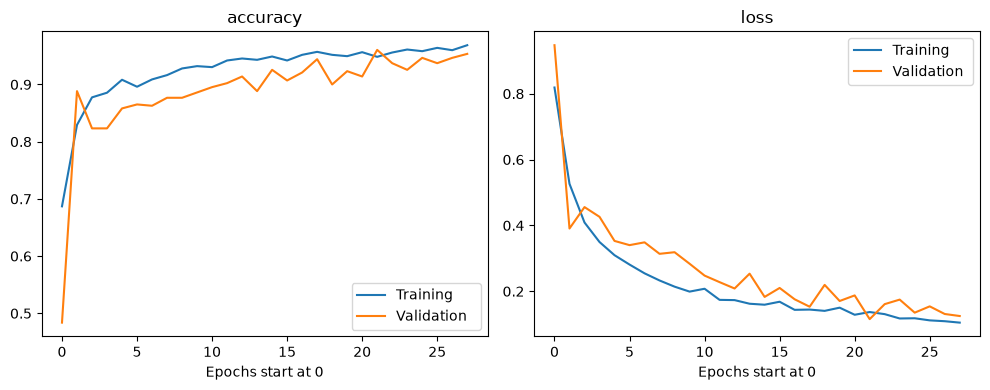

In [9]:
plt.figure(figsize=(10,4))
plt.subplot(1,2,1)
plt.plot(history.history['accuracy'], label='Training  ') 
plt.plot(history.history['val_accuracy'], label='Validation  ')
plt.title('accuracy')
plt.xlabel('Epochs start at 0')
plt.legend()


plt.subplot(1,2,2)
plt.plot(history.history['loss'], label='Training ')
plt.plot(history.history['val_loss'], label='Validation ')
plt.title('loss')
plt.xlabel('Epochs start at 0')
plt.legend()    

plt.tight_layout()
plt.show()

# Confusion Matrix

validation accuracy:0.96 not test accuracy


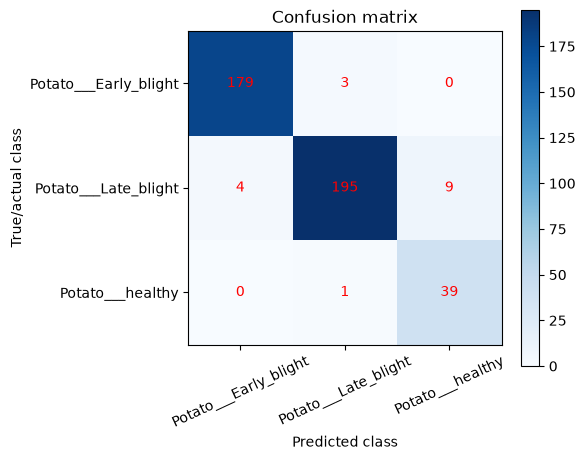

In [10]:
all_true,all_pred=[],[]
for batch_images,batch_labels in validation_ds:
    scores=model.predict(batch_images,verbose=0)
    all_true.extend(batch_labels.numpy())
    all_pred.extend(np.argmax(scores,axis=1))

matrix=tf.math.confusion_matrix(all_true,all_pred,num_classes=len(class_names)).numpy()

accuracy=np.mean(np.array(all_true)==np.array(all_pred))
print(f"validation accuracy:{accuracy:.2f} not test accuracy")

plt.figure(figsize=(6,5))
plt.imshow(matrix, cmap="Blues")
plt.colorbar()

plt.xticks(range(3),[s.replace("potato__","") for s in class_names],rotation=25)
plt.yticks(range(3),[s.replace("potato__","") for s in class_names]) 
plt.xlabel("Predicted class")
plt.ylabel("True/actual class")
plt.title("Confusion matrix")  


for i in range(3):
    for j in range(3):
        plt.text(j,i, matrix[i,j], ha="center", va="center", color="red")
plt.tight_layout()
plt.show()

# Save the model

In [11]:
(ROOT/ "model").mkdir(exist_ok=True)
model.save(ROOT / "model"/ "potato_cnn_model.keras")
(ROOT/ "model"/ "class_names.txt").write_text("\n".join(class_names),encoding="utf-8")
print("model saved to potato_cnn_model.keras and class names saved to classification_report.txt")

model saved to potato_cnn_model.keras and class names saved to classification_report.txt


# Prediction on unseen data

model score 0.90
Potato___Early_blight : 0.07
Potato___Late_blight : 0.03
Potato___healthy : 0.90


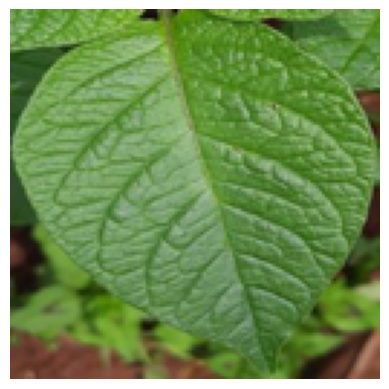

In [12]:
image_path = ROOT / "sample_images" / "image.png"
if image_path.is_file():
    with Image.open(image_path) as file:
        image = file.convert("RGB").resize(IMG_SIZE)
    x=np.expand_dims(np.array(image,dtype=np.float32),axis=0)
    scores=model.predict(x,verbose=0)[0]
    best= int(np.argmax(scores))
    print("model score",f"{scores[best]:.2f}")
    for name, score in zip(class_names,scores):
        print(f"{name.replace('potato__','')} : {score:.2f}")
    plt.imshow(image)
    plt.axis("off")
    plt.show()
else:
    print(" place an image named leaf.jpg beside this notebook and run cell again")
    